1.6.1


In [ ]:

%pip install -q scikit-learn==1.6.1 scikeras==0.13.0



LAB ASSIGNMENT 7 - PIMA INDIANS DIABETES

Upload your ZIP file containing the diabetes CSV.


Saving archive (8).zip to archive (8) (5).zip

CSV selected: /content/pima_diabetes_dataset/pima-indians-diabetes.csv

Dataset shape: (768, 9)

First five rows:
   pregnancies  glucose  bloodpressure  skinthickness  insulin   bmi  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   diabetespedigreefunction  age  outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  

Missing values:
pregnancies                 0
glucose                     0
bloodpressure               0
skinthickness               0
insul

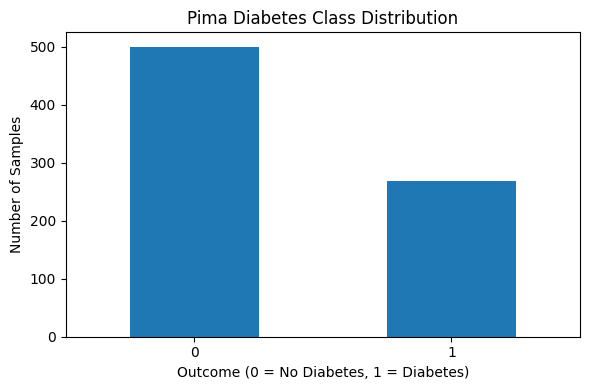


Training samples: 614
Testing samples: 154
Input features: 8

Starting GridSearchCV
Parameter combinations: 32
Total CV fits: 96
This may take some time. Please keep the Colab session active.
Fitting 3 folds for each of 32 candidates, totalling 96 fits

GRID SEARCH COMPLETED

Best parameters:
{'classifier__activation': 'tanh', 'classifier__batch_size': 32, 'classifier__dropout_rate': 0.4, 'classifier__epochs': 20, 'classifier__hidden_neurons': 32, 'classifier__kernel_initializer': 'glorot_uniform', 'classifier__learning_rate': 0.001}

Best mean cross-validation F1-score: 0.6817

FINAL TEST METRICS
Accuracy : 0.7273
Precision: 0.6111
Recall   : 0.6111
F1-score : 0.6111
AUROC    : 0.8048

Classification report:
              precision    recall  f1-score   support

 No Diabetes       0.79      0.79      0.79       100
    Diabetes       0.61      0.61      0.61        54

    accuracy                           0.73       154
   macro avg       0.70      0.70      0.70       154
weighted

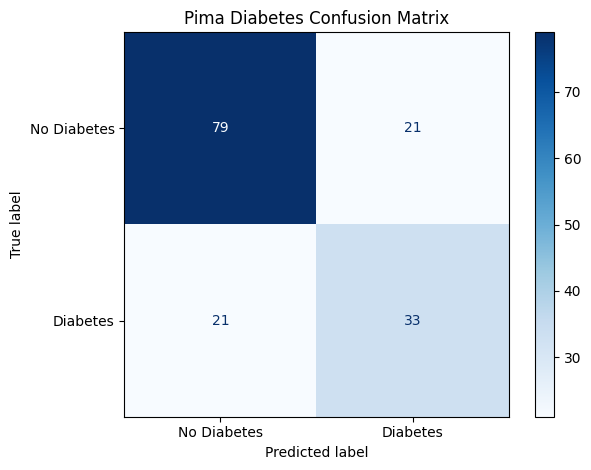

True negatives : 79
False positives: 21
False negatives: 21
True positives : 33

Results saved in: /content/lab7_results


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


LAB ASSIGNMENT 7 FINISHED.


In [ ]:
import os
import zipfile
import warnings
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from google.colab import files
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
keras.utils.set_random_seed(SEED)

print("=" * 65)
print("LAB ASSIGNMENT 7 - PIMA INDIANS DIABETES")
print("=" * 65)


# TASK 1: UPLOAD ZIP AND LOAD CSV


print("\nUpload your ZIP file containing the diabetes CSV.")
uploaded = files.upload()

zip_names = [
    name for name in uploaded if name.lower().endswith(".zip")
]
if not zip_names:
    raise ValueError("Please upload a ZIP file containing a CSV.")

zip_path = os.path.join("/content", zip_names[0])
extract_dir = "/content/pima_diabetes_dataset"
os.makedirs(extract_dir, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zf:
    zf.extractall(extract_dir)

csv_paths = [
    os.path.join(root, name)
    for root, _, names in os.walk(extract_dir)
    for name in names
    if name.lower().endswith(".csv")
]

if not csv_paths:
    raise FileNotFoundError("No CSV file was found inside the ZIP.")

# Prefer filenames containing diabetes or pima
preferred = [
    p for p in csv_paths
    if "diabetes" in os.path.basename(p).lower()
    or "pima" in os.path.basename(p).lower()
]
csv_path = preferred[0] if preferred else csv_paths[0]
print("\nCSV selected:", csv_path)

# Read CSV and identify its header format
expected_columns = [
    "Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
    "Insulin", "BMI", "DiabetesPedigreeFunction", "Age", "Outcome"
]

df = pd.read_csv(csv_path)

if df.shape[1] == 9:
    normalized = [
        str(c).strip().lower().replace("_", "").replace(" ", "")
        for c in df.columns
    ]
    header_present = any(
        c in {
            "pregnancies", "glucose", "bloodpressure",
            "skinthickness", "insulin", "bmi", "outcome"
        }
        for c in normalized
    )

    if not header_present:
        df = pd.read_csv(
            csv_path, header=None, names=expected_columns
        )

df.columns = [
    str(c).strip().lower().replace("_", "").replace(" ", "")
    for c in df.columns
]

target_candidates = [
    "outcome", "class", "diabetes", "target", "label"
]
target_col = next(
    (c for c in target_candidates if c in df.columns), None
)

if target_col is None:
    if df.shape[1] == 9:
        target_col = df.columns[-1]
    else:
        raise ValueError(
            f"Could not identify the target column. Columns: {list(df.columns)}"
        )

df = df.apply(pd.to_numeric, errors="coerce")
df = df.dropna(subset=[target_col]).reset_index(drop=True)

y = df[target_col].astype(int)
X = df.drop(columns=[target_col])

if not set(y.unique()).issubset({0, 1}):
    raise ValueError(
        f"Expected binary target 0/1, found {sorted(y.unique())}"
    )

if X.shape[1] == 0:
    raise ValueError("No input features were found.")

print("\nDataset shape:", df.shape)
print("\nFirst five rows:")
print(df.head())

print("\nMissing values:")
print(df.isnull().sum())

print("\nClass counts:")
print(y.value_counts().sort_index().rename(
    index={0: "No Diabetes", 1: "Diabetes"}
))

y.value_counts().sort_index().plot(kind="bar", figsize=(6, 4))
plt.title("Pima Diabetes Class Distribution")
plt.xlabel("Outcome (0 = No Diabetes, 1 = Diabetes)")
plt.ylabel("Number of Samples")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


# TASK 2: PREPROCESSING AND DATA SPLITTING


# In the classic Pima dataset, zero values in these measurement
# columns usually mean missing values. Only modify columns present.
for col in [
    "glucose", "bloodpressure", "skinthickness", "insulin", "bmi"
]:
    if col in X.columns:
        X[col] = X[col].replace(0, np.nan)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Input features:", X_train.shape[1])


# TASK 3: CUSTOM KERAS CLASSIFIER
# Avoids SciKeras and sklearn estimator-tag errors


class KerasNNClassifier(ClassifierMixin, BaseEstimator):

    def __init__(
        self,
        hidden_neurons=16,
        learning_rate=0.001,
        activation="relu",
        dropout_rate=0.2,
        kernel_initializer="glorot_uniform",
        batch_size=16,
        epochs=30,
        verbose=0
    ):
        self.hidden_neurons = hidden_neurons
        self.learning_rate = learning_rate
        self.activation = activation
        self.dropout_rate = dropout_rate
        self.kernel_initializer = kernel_initializer
        self.batch_size = batch_size
        self.epochs = epochs
        self.verbose = verbose

    def fit(self, X, y):
        keras.backend.clear_session()
        tf.random.set_seed(SEED)

        X = np.asarray(X, dtype=np.float32)
        y = np.asarray(y, dtype=int)

        self.classes_ = np.unique(y)

        self.model_ = keras.Sequential([
            layers.Input(shape=(X.shape[1],)),
            layers.Dense(
                self.hidden_neurons,
                activation=self.activation,
                kernel_initializer=self.kernel_initializer
            ),
            layers.Dropout(self.dropout_rate),
            layers.Dense(
                max(self.hidden_neurons // 2, 4),
                activation=self.activation,
                kernel_initializer=self.kernel_initializer
            ),
            layers.Dropout(self.dropout_rate),
            layers.Dense(1, activation="sigmoid")
        ])

        self.model_.compile(
            optimizer=keras.optimizers.Adam(
                learning_rate=self.learning_rate
            ),
            loss="binary_crossentropy",
            metrics=["accuracy"]
        )

        self.model_.fit(
            X, y,
            epochs=self.epochs,
            batch_size=self.batch_size,
            verbose=self.verbose
        )

        return self

    def predict_proba(self, X):
        X = np.asarray(X, dtype=np.float32)
        positive = self.model_.predict(X, verbose=0).ravel()
        return np.column_stack([1.0 - positive, positive])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)


# Preprocessing is fitted within each CV fold to avoid data leakage.
pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", KerasNNClassifier())
])


# GRID SEARCH: ALL SEVEN REQUIRED HYPERPARAMETERS



param_grid = {
    "classifier__batch_size": [16, 32],
    "classifier__epochs": [20],
    "classifier__learning_rate": [0.001],
    "classifier__kernel_initializer": ["glorot_uniform", "he_normal"],
    "classifier__activation": ["relu", "tanh"],
    "classifier__dropout_rate": [0.2, 0.4],
    "classifier__hidden_neurons": [16, 32]
}

cv = StratifiedKFold(
    n_splits=3, shuffle=True, random_state=SEED
)

grid = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=1,
    verbose=1,
    refit=True,
    error_score="raise"
)

n_combinations = int(np.prod([
    len(values) for values in param_grid.values()
]))

print("\nStarting GridSearchCV")
print("Parameter combinations:", n_combinations)
print("Total CV fits:", n_combinations * cv.get_n_splits())
print("This may take some time. Please keep the Colab session active.")

grid.fit(X_train, y_train)

print("\nGRID SEARCH COMPLETED")
print("\nBest parameters:")
print(grid.best_params_)
print("\nBest mean cross-validation F1-score:",
      round(grid.best_score_, 4))

best_model = grid.best_estimator_


# EVALUATION ON THE HELD-OUT TEST SET


y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
auroc = roc_auc_score(y_test, y_prob)

print("\n" + "=" * 55)
print("FINAL TEST METRICS")
print("=" * 55)
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")
print(f"AUROC    : {auroc:.4f}")

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["No Diabetes", "Diabetes"],
    zero_division=0
))

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Diabetes", "Diabetes"]
)
disp.plot(cmap="Blues", values_format="d")
plt.title("Pima Diabetes Confusion Matrix")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print("True negatives :", tn)
print("False positives:", fp)
print("False negatives:", fn)
print("True positives :", tp)


# SAVE RESULTS AND DOWNLOAD THEM


output_dir = "/content/lab7_results"
os.makedirs(output_dir, exist_ok=True)

pd.DataFrame(grid.cv_results_).sort_values(
    "rank_test_score"
).to_csv(
    os.path.join(output_dir, "grid_search_results.csv"),
    index=False
)

pd.DataFrame([{
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1_score": f1,
    "AUROC": auroc,
    "Best_CV_F1": grid.best_score_
}]).to_csv(
    os.path.join(output_dir, "test_metrics.csv"),
    index=False
)

# Save the trained Keras network separately.
best_model.named_steps["classifier"].model_.save(
    os.path.join(output_dir, "best_diabetes_model.keras")
)

# Save the complete preprocessing + model pipeline.
import joblib
joblib.dump(
    best_model,
    os.path.join(output_dir, "best_diabetes_pipeline.joblib")
)

with open(os.path.join(output_dir, "assignment_summary.txt"), "w") as f:
    f.write("LAB ASSIGNMENT 7: PIMA INDIANS DIABETES\n\n")
    f.write(f"CSV file: {os.path.basename(csv_path)}\n")
    f.write(f"Total samples: {len(df)}\n")
    f.write(f"Features: {X.shape[1]}\n")
    f.write(f"Training samples: {len(X_train)}\n")
    f.write(f"Testing samples: {len(X_test)}\n\n")
    f.write(f"Best parameters: {grid.best_params_}\n")
    f.write(f"Best CV F1-score: {grid.best_score_:.4f}\n")
    f.write(f"Test Accuracy: {accuracy:.4f}\n")
    f.write(f"Test Precision: {precision:.4f}\n")
    f.write(f"Test Recall: {recall:.4f}\n")
    f.write(f"Test F1-score: {f1:.4f}\n")
    f.write(f"Test AUROC: {auroc:.4f}\n")

archive = shutil.make_archive(
    "/content/lab7_results", "zip", output_dir
)

print("\nResults saved in:", output_dir)
print("Downloading results ZIP...")
files.download(archive)

print("\nLAB ASSIGNMENT 7 FINISHED.")
